In [1]:
import re
import string
import numpy as np
import pandas as pd
import tensorflow as tf

In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Embedding, LSTM, Dense, Dropout, SpatialDropout1D,
    LayerNormalization, TextVectorization)
from sklearn.model_selection import train_test_split

In [4]:
# ==========================================
# 1. CONFIGURATION & DATA PREP
# ==========================================
tf.keras.utils.set_random_seed(42)

MAX_WORDS = 30000
MAX_LEN = 200
EMBEDDING_DIM = 128
BATCH_SIZE = 128
EPOCHS = 5
LABELS = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

df = pd.read_csv('comments.csv')
df['comment_text'] = df['comment_text'].fillna("")

In [5]:
def custom_standardization(input_data):
    lowercase = tf.strings.lower(input_data)
    no_ips = tf.strings.regex_replace(lowercase, r'\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b', '')
    no_newlines = tf.strings.regex_replace(no_ips, r'\n|\r', ' ')
    return tf.strings.regex_replace(no_newlines, f'[{re.escape(string.punctuation)}]', '')

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42)

In [6]:
def build_dataset(texts, labels, is_training=True):
    ds = tf.data.Dataset.from_tensor_slices((texts, labels))
    if is_training:
        ds = ds.shuffle(10000)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = build_dataset(train_df['comment_text'].values, train_df[LABELS].values, True)
val_ds = build_dataset(val_df['comment_text'].values, val_df[LABELS].values, False)

vectorizer = TextVectorization(
    max_tokens=MAX_WORDS,
    output_sequence_length=MAX_LEN,
    standardize=custom_standardization,
    output_mode='int'
)
vectorizer.adapt(train_df['comment_text'].values)

train_ds = train_ds.map(lambda x, y: (vectorizer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (vectorizer(x), y), num_parallel_calls=tf.data.AUTOTUNE)

In [7]:
# ==========================================
# 2. DEFINE THE 3 PURE LSTM VARIANTS
# ==========================================
def build_baseline_lstm():
    return Sequential([
        Embedding(MAX_WORDS, EMBEDDING_DIM, input_length=MAX_LEN),
        LSTM(128, dropout=0.2),
        Dense(64, activation='relu'),
        Dense(len(LABELS), activation='sigmoid')
    ], name="1_Baseline_LSTM")

def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, EMBEDDING_DIM, input_length=MAX_LEN),
        LSTM(128, return_sequences=True, dropout=0.2),
        LSTM(64, return_sequences=False, dropout=0.2),
        Dense(64, activation='relu'),
        Dense(len(LABELS), activation='sigmoid')
    ], name="2_Stacked_Deep_LSTM")

def build_regularized_lstm():
    return Sequential([
        Embedding(MAX_WORDS, EMBEDDING_DIM, input_length=MAX_LEN),
        SpatialDropout1D(0.3),
        LSTM(128, dropout=0.25),
        LayerNormalization(),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(len(LABELS), activation='sigmoid')
    ], name="3_Regularized_Norm_LSTM")

In [8]:
# ==========================================
# 3. TRAIN & MEASURE STABILITY
# ==========================================
models = [build_baseline_lstm(), build_stacked_lstm(), build_regularized_lstm()]
results = []

for model in models:
    print(f"\n{'='*40}\nTraining: {model.name}\n{'='*40}")

    # Gradient clipping (clipnorm=1.0) prevents exploding gradients in RNNs
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=[tf.keras.metrics.AUC(multi_label=True, name='auc')]
    )

    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)

    val_losses = history.history['val_loss']
    val_aucs = history.history['val_auc']
    train_losses = history.history['loss']

    # Stability Metrics:
    # 1. Loss Volatility: Standard deviation of validation loss across epochs (lower = smoother)
    # 2. Overfit Gap: Difference between final train loss and validation loss (lower = better generalization)
    loss_volatility = np.std(val_losses)
    overfit_gap = abs(val_losses[-1] - train_losses[-1])
    best_auc = max(val_aucs)
    min_val_loss = min(val_losses)

    results.append({
        'Model': model.name,
        'Best Val AUC': round(best_auc, 4),
        'Min Val Loss': round(min_val_loss, 4),
        'Loss Volatility (Std)': round(loss_volatility, 5),
        'Final Overfit Gap': round(overfit_gap, 4)
    })


Training: 1_Baseline_LSTM
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1122/1122 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - auc: 0.7236 - loss: 0.1208 - val_auc: 0.9456 - val_loss: 0.0567
Epoch 2/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 35s 24ms/step - auc: 0.9580 - loss: 0.0508 - val_auc: 0.9565 - val_loss: 0.0499
Epoch 3/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 41s 24ms/step - auc: 0.9688 - loss: 0.0438 - val_auc: 0.9550 - val_loss: 0.0501
Epoch 4/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - auc: 0.9750 - loss: 0.0399 - val_auc: 0.9555 - val_loss: 0.0521
Epoch 5/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - auc: 0.9769 - loss: 0.0367 - val_auc: 0.9502 - val_loss: 0.0565

Training: 2_Stacked_Deep_LSTM
Epoch 1/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 43s 35ms/step - auc: 0.7462 - loss: 0.1194 - val_auc: 0.9323 - val_loss: 0.0655
Epoch 2/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 39s 35ms/step - auc: 0.9498 - loss: 0.0573 - val_auc: 0.9464 - val_loss: 0.0521
Epoch 3/5
1122/1122 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - auc: 0.9660 - loss: 0.0480 - val_auc: 0.9541 - val_loss: 0.0509
Epoch 4/5
1

In [9]:
# ==========================================
# 4. SUMMARY COMPARISON REPORT
# ==========================================
print("\n\n" + "="*65)
print("FINAL MODEL STABILITY & PERFORMANCE COMPARISON")
print("="*65)
summary_df = pd.DataFrame(results)
print(summary_df.to_string(index=False))



FINAL MODEL STABILITY & PERFORMANCE COMPARISON
                  Model  Best Val AUC  Min Val Loss  Loss Volatility (Std)  Final Overfit Gap
        1_Baseline_LSTM        0.9565        0.0499                0.00300             0.0199
    2_Stacked_Deep_LSTM        0.9557        0.0509                0.00546             0.0137
3_Regularized_Norm_LSTM        0.9597        0.0478                0.04126             0.0006


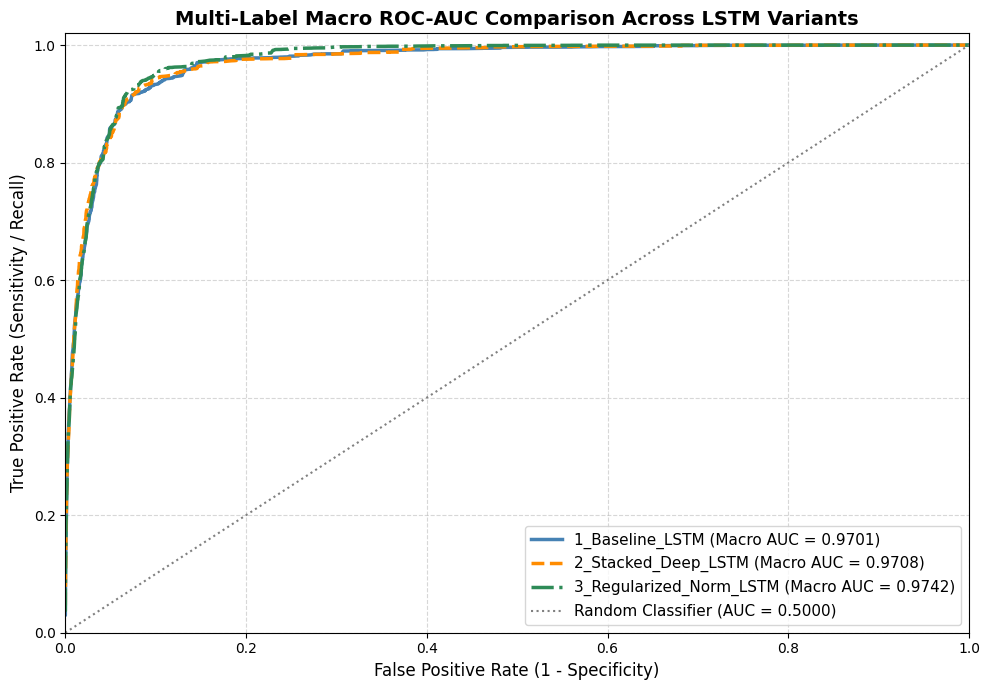


PER-CLASS ROC-AUC BREAKDOWN ACROSS ALL 6 TOXICITY LABELS
                  Model  Macro AUC  toxic  severe_toxic  obscene  threat  insult  identity_hate
        1_Baseline_LSTM     0.9701 0.9676        0.9862   0.9853  0.9547  0.9780         0.9487
    2_Stacked_Deep_LSTM     0.9708 0.9697        0.9870   0.9877  0.9506  0.9814         0.9480
3_Regularized_Norm_LSTM     0.9742 0.9767        0.9857   0.9903  0.9519  0.9829         0.9573


In [15]:
# ==========================================
# 10. MULTI-LABEL MACRO ROC-AUC CURVE COMPARISON
# ==========================================
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Extract true validation labels
y_true = val_df[LABELS].values

plt.figure(figsize=(10, 7))

# Custom styling for each model curve
curve_styles = [
    {'color': 'steelblue', 'linestyle': '-', 'linewidth': 2.5},
    {'color': 'darkorange', 'linestyle': '--', 'linewidth': 2.5},
    {'color': 'seagreen', 'linestyle': '-.', 'linewidth': 2.5}
]

roc_summary = []

for idx, model in enumerate(models):
    # Predict probabilities on the validation dataset
    y_pred_probs = model.predict(val_ds, verbose=0)

    # Compute ROC curve and ROC area for each of the 6 toxicity classes
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(LABELS)):
        fpr[i], tpr[i], _ = roc_curve(y_true[:, i], y_pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Compute macro-average ROC curve across all 6 labels
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(LABELS))]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(len(LABELS)):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= len(LABELS)

    macro_auc = auc(all_fpr, mean_tpr)

    # Store per-class AUC scores for table printout
    class_scores = {LABELS[i]: round(roc_auc[i], 4) for i in range(len(LABELS))}
    class_scores['Model'] = model.name
    class_scores['Macro AUC'] = round(macro_auc, 4)
    roc_summary.append(class_scores)

    # Plot the macro-average ROC curve
    style = curve_styles[idx]
    plt.plot(
        all_fpr,
        mean_tpr,
        label=f"{model.name} (Macro AUC = {macro_auc:.4f})",
        color=style['color'],
        linestyle=style['linestyle'],
        linewidth=style['linewidth']
    )

# Plot random guessing baseline
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', linewidth=1.5, label='Random Classifier (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Multi-Label Macro ROC-AUC Comparison Across LSTM Variants', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('lstm_roc_auc_comparison.png', dpi=300)
plt.show()

# Print per-class AUC breakdown table
print("\n" + "="*85)
print("PER-CLASS ROC-AUC BREAKDOWN ACROSS ALL 6 TOXICITY LABELS")
print("="*85)
cols = ['Model', 'Macro AUC'] + LABELS
roc_df = pd.DataFrame(roc_summary)[cols]
print(roc_df.to_string(index=False))

In [10]:
# ==========================================
# 5. K-FOLD CROSS-VALIDATION (FOLLOW-UP CHECK)
# ==========================================
import gc
from sklearn.model_selection import KFold

print("\n\n" + "="*65)
print("RUNNING K-FOLD CROSS-VALIDATION ACROSS RANDOM SPLITS")
print("="*65)

N_SPLITS = 3
X_all = df['comment_text'].values
y_all = df[LABELS].values

model_builders = [
    ("1_Baseline_LSTM", build_baseline_lstm),
    ("2_Stacked_Deep_LSTM", build_stacked_lstm),
    ("3_Regularized_Norm_LSTM", build_regularized_lstm)
]

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
kfold_results = []

for model_name, build_fn in model_builders:
    print(f"\n>>> {N_SPLITS}-Fold CV for: {model_name} <<<")
    fold_aucs = []
    fold_losses = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_all, y_all), 1):
        print(f"\n[{model_name} - Fold {fold}/{N_SPLITS}]")
        X_tr, y_tr = X_all[train_idx], y_all[train_idx]
        X_va, y_va = X_all[val_idx], y_all[val_idx]

        # Adapt vectorizer on current fold's training split to prevent data leakage
        fold_vectorizer = TextVectorization(
            max_tokens=MAX_WORDS,
            output_sequence_length=MAX_LEN,
            standardize=custom_standardization,
            output_mode='int'
        )
        fold_vectorizer.adapt(X_tr)

        tr_ds = build_dataset(X_tr, y_tr, True).map(
            lambda x, y: (fold_vectorizer(x), y), num_parallel_calls=tf.data.AUTOTUNE
        )
        va_ds = build_dataset(X_va, y_va, False).map(
            lambda x, y: (fold_vectorizer(x), y), num_parallel_calls=tf.data.AUTOTUNE
        )

        # Build fresh model weights for this fold
        fold_model = build_fn()
        fold_model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
            loss='binary_crossentropy',
            metrics=[tf.keras.metrics.AUC(multi_label=True, name='auc')]
        )

        history = fold_model.fit(tr_ds, validation_data=va_ds, epochs=EPOCHS, verbose=1)

        fold_aucs.append(max(history.history['val_auc']))
        fold_losses.append(min(history.history['val_loss']))

        # Clear memory between folds
        tf.keras.backend.clear_session()
        gc.collect()

    kfold_results.append({
        'Model': model_name,
        'K-Fold Mean AUC': round(np.mean(fold_aucs), 4),
        'Cross-Fold AUC Std': round(np.std(fold_aucs), 5),
        'K-Fold Mean Loss': round(np.mean(fold_losses), 4),
        'Cross-Fold Loss Std': round(np.std(fold_losses), 5)
    })

# ==========================================
# 6. MERGED FINAL STABILITY REPORT
# ==========================================
print("\n\n" + "="*80)
print("CONSOLIDATED REPORT: SINGLE-SPLIT + K-FOLD STABILITY")
print("="*80)
kfold_df = pd.DataFrame(kfold_results)
final_df = pd.merge(summary_df, kfold_df, on='Model')
print(final_df.to_string(index=False))



RUNNING K-FOLD CROSS-VALIDATION ACROSS RANDOM SPLITS

>>> 3-Fold CV for: 1_Baseline_LSTM <<<

[1_Baseline_LSTM - Fold 1/3]
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


832/832 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - auc: 0.5049 - loss: 0.1450 - val_auc: 0.5080 - val_loss: 0.1425
Epoch 2/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - auc: 0.7347 - loss: 0.1154 - val_auc: 0.9429 - val_loss: 0.0596
Epoch 3/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 27s 33ms/step - auc: 0.9568 - loss: 0.0514 - val_auc: 0.9617 - val_loss: 0.0509
Epoch 4/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - auc: 0.9672 - loss: 0.0436 - val_auc: 0.9627 - val_loss: 0.0500
Epoch 5/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - auc: 0.9741 - loss: 0.0389 - val_auc: 0.9563 - val_loss: 0.0525

[1_Baseline_LSTM - Fold 2/3]
Epoch 1/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 27s 29ms/step - auc: 0.5022 - loss: 0.1474 - val_auc: 0.5082 - val_loss: 0.1388
Epoch 2/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - auc: 0.5128 - loss: 0.1424 - val_auc: 0.5262 - val_loss: 0.1377
Epoch 3/5
832/832 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - auc: 0.9183 - loss: 0.0748 - val_auc: 0.9617 - val_loss: 0.0504
Epoch 4/5
832/832 ━━━━━━━━━━

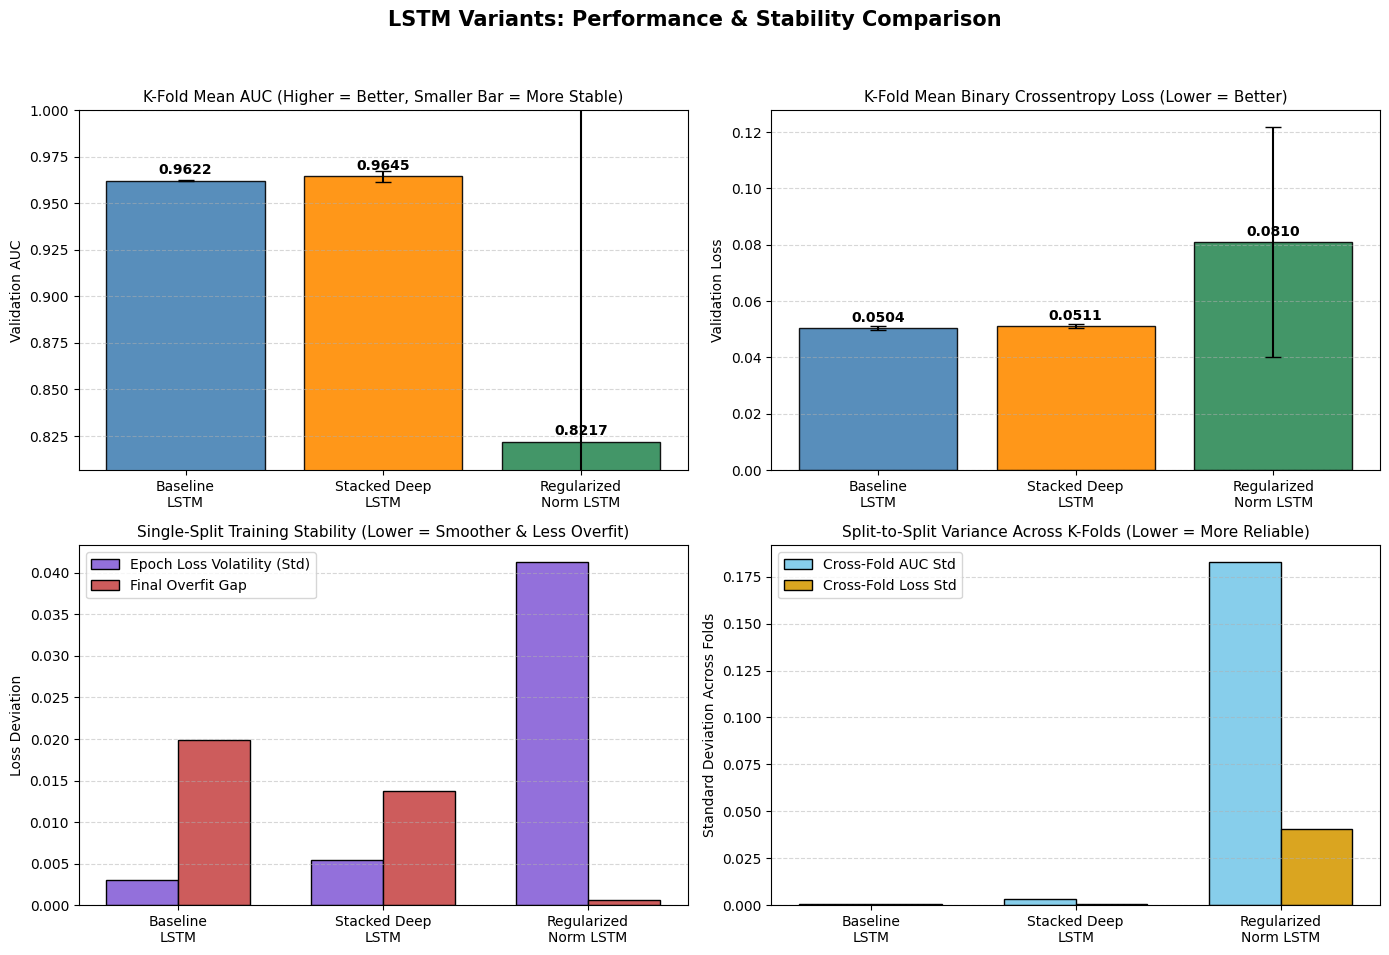

Saved stability dashboard to 'lstm_stability_comparison.png'


In [12]:
# ==========================================
# 7. PLOT STABILITY & PERFORMANCE DASHBOARD
# ==========================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('LSTM Variants: Performance & Stability Comparison', fontsize=15, fontweight='bold')

models_labels = ['Baseline\nLSTM', 'Stacked Deep\nLSTM', 'Regularized\nNorm LSTM']
colors = ['steelblue', 'darkorange', 'seagreen']

# --- Plot 1: K-Fold Mean AUC with Cross-Fold Std Error Bars ---
ax1 = axes[0, 0]
bars1 = ax1.bar(
    models_labels,
    final_df['K-Fold Mean AUC'],
    yerr=final_df['Cross-Fold AUC Std'],
    capsize=6,
    color=colors,
    edgecolor='black',
    alpha=0.9
)
ax1.set_title('K-Fold Mean AUC (Higher = Better, Smaller Bar = More Stable)', fontsize=11)
ax1.set_ylabel('Validation AUC')
min_auc = final_df['K-Fold Mean AUC'].min() - 0.015
ax1.set_ylim([max(0.5, min_auc), 1.0])
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

# --- Plot 2: K-Fold Mean Loss with Cross-Fold Std Error Bars ---
ax2 = axes[0, 1]
bars2 = ax2.bar(
    models_labels,
    final_df['K-Fold Mean Loss'],
    yerr=final_df['Cross-Fold Loss Std'],
    capsize=6,
    color=colors,
    edgecolor='black',
    alpha=0.9
)
ax2.set_title('K-Fold Mean Binary Crossentropy Loss (Lower = Better)', fontsize=11)
ax2.set_ylabel('Validation Loss')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.001, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

# --- Plot 3: Training Stability (Epoch Volatility vs Overfit Gap) ---
ax3 = axes[1, 0]
x = np.arange(len(models_labels))
width = 0.35

rects1 = ax3.bar(x - width/2, final_df['Loss Volatility (Std)'], width, label='Epoch Loss Volatility (Std)', color='mediumpurple', edgecolor='black')
rects2 = ax3.bar(x + width/2, final_df['Final Overfit Gap'], width, label='Final Overfit Gap', color='indianred', edgecolor='black')

ax3.set_title('Single-Split Training Stability (Lower = Smoother & Less Overfit)', fontsize=11)
ax3.set_xticks(x)
ax3.set_xticklabels(models_labels)
ax3.set_ylabel('Loss Deviation')
ax3.legend()
ax3.grid(axis='y', linestyle='--', alpha=0.5)

# --- Plot 4: Cross-Fold Variance (Split-to-Split Consistency) ---
ax4 = axes[1, 1]
rects3 = ax4.bar(x - width/2, final_df['Cross-Fold AUC Std'], width, label='Cross-Fold AUC Std', color='skyblue', edgecolor='black')
rects4 = ax4.bar(x + width/2, final_df['Cross-Fold Loss Std'], width, label='Cross-Fold Loss Std', color='goldenrod', edgecolor='black')

ax4.set_title('Split-to-Split Variance Across K-Folds (Lower = More Reliable)', fontsize=11)
ax4.set_xticks(x)
ax4.set_xticklabels(models_labels)
ax4.set_ylabel('Standard Deviation Across Folds')
ax4.legend()
ax4.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('lstm_stability_comparison.png', dpi=300)
plt.show()

print("Saved stability dashboard to 'lstm_stability_comparison.png'")


In [14]:
# ==========================================
# 8. STATISTICAL RELIABILITY & STABILITY TESTS (FROM final_df)
# ==========================================
from scipy import stats

print("\n" + "="*80)
print("STATISTICAL RELIABILITY REPORT (95% CI & COEFFICIENT OF VARIATION)")
print("="*80)

stat_rows = []
n_folds = N_SPLITS  # Uses your existing N_SPLITS = 3

for _, row in final_df.iterrows():
    model_name = row['Model']
    mean_auc = row['K-Fold Mean AUC']
    pop_std_auc = row['Cross-Fold AUC Std']
    mean_loss = row['K-Fold Mean Loss']
    pop_std_loss = row['Cross-Fold Loss Std']

    # Convert numpy population std (ddof=0) to unbiased sample std (ddof=1)
    sample_std_auc = pop_std_auc * np.sqrt(n_folds / (n_folds - 1))
    sample_std_loss = pop_std_loss * np.sqrt(n_folds / (n_folds - 1))

    # Standard Error of the Mean (SEM)
    se_auc = sample_std_auc / np.sqrt(n_folds)

    # 95% Confidence Interval using Student's t-distribution
    ci_low, ci_high = stats.t.interval(0.95, df=n_folds-1, loc=mean_auc, scale=se_auc)

    # Coefficient of Variation (Relative Volatility %)
    cv_auc = (sample_std_auc / mean_auc) * 100
    cv_loss = (sample_std_loss / mean_loss) * 100

    stat_rows.append({
        'Model': model_name,
        'Mean AUC': round(mean_auc, 4),
        '95% CI (AUC)': f"[{max(0, ci_low):.4f}, {min(1, ci_high):.4f}]",
        'AUC CV (%)': f"{cv_auc:.3f}%",
        'Loss CV (%)': f"{cv_loss:.3f}%"
    })

stat_df = pd.DataFrame(stat_rows)
print(stat_df.to_string(index=False))

# ==========================================
# 9. HYPOTHESIS TESTING FROM SUMMARY STATS (WELCH'S T-TEST & F-TEST)
# ==========================================
print("\n" + "="*85)
print("HYPOTHESIS TESTS: MEAN ACCURACY (WELCH'S T-TEST) & STABILITY (F-TEST)")
print("="*85)

def get_stats(model_label):
    r = final_df[final_df['Model'] == model_label].iloc[0]
    mean = r['K-Fold Mean AUC']
    s_std = r['Cross-Fold AUC Std'] * np.sqrt(n_folds / (n_folds - 1))
    return mean, s_std

m_base, s_base = get_stats('1_Baseline_LSTM')
m_stack, s_stack = get_stats('2_Stacked_Deep_LSTM')
m_reg, s_reg = get_stats('3_Regularized_Norm_LSTM')

comparisons = [
    ("Stacked Deep vs. Baseline", m_stack, s_stack, m_base, s_base),
    ("Baseline vs. Regularized", m_base, s_base, m_reg, s_reg),
    ("Stacked Deep vs. Regularized", m_stack, s_stack, m_reg, s_reg)
]

test_rows = []
for pair_name, mean_a, std_a, mean_b, std_b in comparisons:
    # 1. Welch's t-test from summary statistics (compares mean accuracy)
    t_stat, t_pval = stats.ttest_ind_from_stats(
        mean1=mean_a, std1=std_a, nobs1=n_folds,
        mean2=mean_b, std2=std_b, nobs2=n_folds,
        equal_var=False
    )

    # 2. Variance Ratio F-test (compares fold-to-fold stability)
    var_a, var_b = std_a**2, std_b**2
    f_stat = max(var_a, var_b) / max(min(var_a, var_b), 1e-12)
    f_pval = 2 * min(stats.f.cdf(f_stat, n_folds-1, n_folds-1), 1 - stats.f.cdf(f_stat, n_folds-1, n_folds-1))

    test_rows.append({
        'Comparison Pair': pair_name,
        'Mean AUC Diff': round(mean_a - mean_b, 4),
        'Welch t-stat': round(t_stat, 4),
        't-test p-value': round(t_pval, 4),
        'Stability F-stat': round(f_stat, 2),
        'F-test p-value': round(f_pval, 4)
    })

hypothesis_df = pd.DataFrame(test_rows)
print(hypothesis_df.to_string(index=False))


STATISTICAL RELIABILITY REPORT (95% CI & COEFFICIENT OF VARIATION)
                  Model  Mean AUC     95% CI (AUC) AUC CV (%) Loss CV (%)
        1_Baseline_LSTM    0.9622 [0.9610, 0.9634]     0.052%      1.628%
    2_Stacked_Deep_LSTM    0.9645 [0.9553, 0.9737]     0.386%      1.582%
3_Regularized_Norm_LSTM    0.8217 [0.2662, 1.0000]    27.212%     61.494%

HYPOTHESIS TESTS: MEAN ACCURACY (WELCH'S T-TEST) & STABILITY (F-TEST)
             Comparison Pair  Mean AUC Diff  Welch t-stat  t-test p-value  Stability F-stat  F-test p-value
   Stacked Deep vs. Baseline         0.0023        1.0604          0.3968             54.98          0.0357
    Baseline vs. Regularized         0.1405        1.0883          0.3901         198285.57          0.0000
Stacked Deep vs. Regularized         0.1428        1.1060          0.3839           3606.71          0.0006


In [16]:
# ==========================================
# 11. REAL-WORLD PRODUCTION DEPLOYMENT BENCHMARK (VALIDATION DATA ONLY)
# ==========================================
import time
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    brier_score_loss, confusion_matrix
)

y_true = val_df[LABELS].values
n_samples = len(y_true)

prod_results = []

for model in models:
    # 1. Measure Real-Time Inference Latency (ms per comment)
    start_time = time.perf_counter()
    y_pred_probs = model.predict(val_ds, verbose=0)
    total_time = time.perf_counter() - start_time
    latency_ms = (total_time / n_samples) * 1000

    # 2. Macro PR-AUC (Stricter than ROC-AUC for imbalanced 90/10 real-world data)
    pr_aucs = [average_precision_score(y_true[:, i], y_pred_probs[:, i]) for i in range(len(LABELS))]
    macro_pr_auc = np.mean(pr_aucs)

    # 3. Optimal Decision Threshold & Macro F1-Score per Class
    best_f1s = []
    optimal_thresholds = []
    for i in range(len(LABELS)):
        precisions, recalls, thresholds = precision_recall_curve(y_true[:, i], y_pred_probs[:, i])
        f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
        best_idx = np.argmax(f1_scores)
        best_f1s.append(f1_scores[best_idx])
        optimal_thresholds.append(thresholds[min(best_idx, len(thresholds)-1)])

    macro_f1 = np.mean(best_f1s)

    # 4. Probability Calibration (Brier Score: Lower = More Trustworthy Confidence Scores)
    brier_scores = [brier_score_loss(y_true[:, i], y_pred_probs[:, i]) for i in range(len(LABELS))]
    mean_brier = np.mean(brier_scores)

    # 5. Overall Moderation Accuracy: False Alarm Rate & Catch Rate (Any-Toxicity Flag)
    y_true_any = (np.sum(y_true, axis=1) > 0).astype(int)
    y_pred_any = (np.any(y_pred_probs >= optimal_thresholds, axis=1)).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true_any, y_pred_any).ravel()
    false_alarm_rate = (fp / (fp + tn)) * 100   # % of clean comments wrongly flagged
    toxic_catch_rate = (tp / (tp + fn)) * 100   # % of real toxic comments caught

    prod_results.append({
        'Model': model.name,
        'Macro PR-AUC': round(macro_pr_auc, 4),
        'Optimal Macro F1': round(macro_f1, 4),
        'Brier Score (Calib.)': round(mean_brier, 5),
        'False Alarm Rate': f"{false_alarm_rate:.2f}%",
        'Toxic Catch Rate': f"{toxic_catch_rate:.2f}%",
        'Latency (ms/msg)': round(latency_ms, 4)
    })

print("\n" + "="*110)
print("REAL-WORLD PRODUCTION DEPLOYMENT BENCHMARK (ON REAL VALIDATION DATA)")
print("="*110)
prod_df = pd.DataFrame(prod_results)
print(prod_df.to_string(index=False))


REAL-WORLD PRODUCTION DEPLOYMENT BENCHMARK (ON REAL VALIDATION DATA)
                  Model  Macro PR-AUC  Optimal Macro F1  Brier Score (Calib.) False Alarm Rate Toxic Catch Rate  Latency (ms/msg)
        1_Baseline_LSTM        0.5061            0.5133               0.01486            1.33%           72.19%            0.2609
    2_Stacked_Deep_LSTM        0.5107            0.5167               0.01430            1.61%           74.73%            0.3058
3_Regularized_Norm_LSTM        0.5092            0.5158               0.01322            1.57%           78.67%            0.1976
